Saving 133883886687166516.jpg to 133883886687166516.jpg


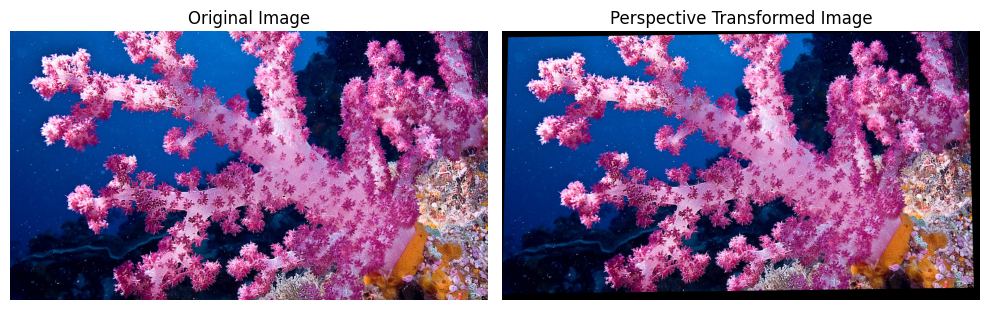

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload an image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read the image
img = cv2.imread(filename)

if img is None:
    print("Error: Image not found!")
else:
    # Get image dimensions
    rows, cols = img.shape[:2]

    # Define four points in the original image
    pts1 = np.float32([
        [0, 0],
        [cols - 1, 0],
        [0, rows - 1],
        [cols - 1, rows - 1]
    ])

    # Define four destination points
    pts2 = np.float32([
        [50, 50],
        [cols - 100, 0],
        [0, rows - 50],
        [cols - 50, rows - 100]
    ])

    # Calculate perspective transformation matrix
    matrix = cv2.getPerspectiveTransform(pts1, pts2)

    # Apply perspective transformation
    transformed = cv2.warpPerspective(
        img, matrix, (cols, rows)
    )

    # Convert BGR to RGB for display
    original_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    transformed_rgb = cv2.cvtColor(
        transformed, cv2.COLOR_BGR2RGB
    )

    # Display original and transformed images
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(transformed_rgb)
    plt.title("Perspective Transformed Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Save and download the output
    cv2.imwrite("perspective_transformed_image.jpg", transformed)
    files.download("perspective_transformed_image.jpg")